In [1]:
import pandas as pd
print("pandas version:", pd.__version__)

pandas version: 3.0.6


In [2]:
path = "../data/raw/DADS5250_Hackathon_Google_Data.xlsx"
signups = pd.read_excel(path, sheet_name="Advertiser Sign-ups")
signups.head()

,Advertiser_ID,Country,Sign_Up_Date,Projected_Annual_Budget
0,A000001,USA,2024-01-01 00:00:00,84376
1,A000002,USA,2024-01-01 00:00:00,57297
2,A000003,USA,2024-01-01 00:00:00,34081
3,A000004,USA,2024-01-01 00:00:00,154506
4,A000005,USA,2024-01-01 00:00:00,23604


In [3]:
signups.shape

(499644, 4)

In [4]:
signups["Country"].value_counts()

Country
USA             60112
India           42330
China           39137
Brazil          36290
UK              36247
Germany         33183
Japan           29865
Canada          26900
France          26859
Australia       23966
Italy           21053
South Korea     18160
Mexico          18140
Spain           15127
Vietnam         14956
Indonesia       12110
Poland          12106
South Africa     9130
Turkey           9049
Thailand         6041
Argentina        5869
UAE              3014
Name: count, dtype: int64

In [5]:
signups["Projected_Annual_Budget"].describe()

count    499644.000000
mean      25265.069125
std       33667.498140
min         500.000000
25%        6422.000000
50%       13981.000000
75%       29779.000000
max      250000.000000
Name: Projected_Annual_Budget, dtype: float64

In [6]:
path = "../data/raw/DADS5250_Hackathon_Google_Data.xlsx"
params = pd.read_excel(path, sheet_name="Agent Salary and Threshold")
params.head()

,Country,Annual_Agent_Salary_USD,Advertiser_Eligibility_Threshold_USD
0,USA,77721,35000
1,UK,51650,27000
2,Germany,51328,26000
3,India,14118,13000
4,Brazil,27950,29000


In [7]:
path = "../data/raw/DADS5250_Hackathon_Google_Data.xlsx"
staff = pd.read_excel(path, sheet_name="Existing Agent Staffing")
staff.head()

,Country,Existing_Agent_Count
0,USA,652
1,UK,589
2,Germany,602
3,India,428
4,Brazil,189


In [8]:
signups["Sign_Up_Date"].dtype

dtype('O')

In [9]:
is_text = signups["Sign_Up_Date"].apply(lambda x: isinstance(x, str))
signups[is_text].head()
is_text.sum()

np.int64(920)

In [10]:
date_text = signups["Sign_Up_Date"].astype(str).str[:10]
date_text.head()

0    2024-01-01
1    2024-01-01
2    2024-01-01
3    2024-01-01
4    2024-01-01
Name: Sign_Up_Date, dtype: str

In [11]:
date_text = date_text.replace("2025-02-29", "2025-02-28")

In [12]:
(date_text == "2025-02-28").sum()

np.int64(1989)

In [13]:
signups["Sign_Up_Date"] = pd.to_datetime(date_text)

In [14]:
signups["Sign_Up_Date"].dtype

dtype('<M8[us]')

In [15]:
df = signups.merge(params, on="Country", how="left")
df.head()

,Advertiser_ID,Country,Sign_Up_Date,Projected_Annual_Budget,Annual_Agent_Salary_USD,Advertiser_Eligibility_Threshold_USD
0,A000001,USA,2024-01-01,84376,77721,35000
1,A000002,USA,2024-01-01,57297,77721,35000
2,A000003,USA,2024-01-01,34081,77721,35000
3,A000004,USA,2024-01-01,154506,77721,35000
4,A000005,USA,2024-01-01,23604,77721,35000


In [16]:
df["Eligibility"] =  df ["Projected_Annual_Budget"] > df["Advertiser_Eligibility_Threshold_USD"] 

In [17]:
df.head()

,Advertiser_ID,Country,Sign_Up_Date,Projected_Annual_Budget,Annual_Agent_Salary_USD,Advertiser_Eligibility_Threshold_USD,Eligibility
0,A000001,USA,2024-01-01,84376,77721,35000,True
1,A000002,USA,2024-01-01,57297,77721,35000,True
2,A000003,USA,2024-01-01,34081,77721,35000,False
3,A000004,USA,2024-01-01,154506,77721,35000,True
4,A000005,USA,2024-01-01,23604,77721,35000,False


In [18]:
df["Eligibility"].mean()

np.float64(0.42497057905228525)

In [19]:
df.groupby("Country")["Eligibility"].mean().sort_values()

Country
China           0.296369
Indonesia       0.302064
Argentina       0.307207
France          0.310920
Brazil          0.315349
Germany         0.323780
UK              0.343339
Canada          0.350372
Australia       0.386840
Thailand        0.392319
South Korea     0.416795
USA             0.434456
Japan           0.447313
Turkey          0.461598
Spain           0.477160
Italy           0.486819
Poland          0.499339
Mexico          0.545590
Vietnam         0.651645
South Africa    0.654984
UAE             0.657598
India           0.682400
Name: Eligibility, dtype: float64

In [20]:
elig = df[df["Eligibility"]]

In [21]:
elig

,Advertiser_ID,Country,Sign_Up_Date,Projected_Annual_Budget,Annual_Agent_Salary_USD,Advertiser_Eligibility_Threshold_USD,Eligibility
0,A000001,USA,2024-01-01,84376,77721,35000,True
1,A000002,USA,2024-01-01,57297,77721,35000,True
3,A000004,USA,2024-01-01,154506,77721,35000,True
7,A000008,USA,2024-01-01,104967,77721,35000,True
8,A000009,USA,2024-01-01,44165,77721,35000,True
...,...,...,...,...,...,...,...
499634,A499635,Thailand,2025-12-31,9038,24289,4000,True
499635,A499636,Thailand,2025-12-31,20091,24289,4000,True
499638,A499639,UAE,2025-12-31,2982,65115,1000,True
499639,A499640,UAE,2025-12-31,1338,65115,1000,True


In [22]:
len(elig)

212334

In [23]:
elig.groupby("Country").size()

Country
Argentina        1803
Australia        9271
Brazil          11444
Canada           9425
China           11599
France           8351
Germany         10744
India           28886
Indonesia        3658
Italy           10249
Japan           13359
Mexico           9897
Poland           6045
South Africa     5980
South Korea      7569
Spain            7218
Thailand         2370
Turkey           4177
UAE              1982
UK              12445
USA             26116
Vietnam          9746
dtype: int64

In [24]:
daily = elig.groupby(["Country", "Sign_Up_Date"]).size()

In [46]:
daily

Country    Sign_Up_Date
Argentina  2024-01-01       3
           2024-01-02       3
           2024-01-03       5
           2024-01-04       4
           2024-01-05       2
                           ..
Vietnam    2025-12-27      16
           2025-12-28      17
           2025-12-29       9
           2025-12-30       8
           2025-12-31      18
Length: 15232, dtype: int64

Length: 15,232.  There are 22 countries × 731 days (2024 was a leap year, so 366 + 365), which is 16,082. So about 850 country-days are missing. 
The reason being -  groupby().size() only creates a row when there’s at least one sign-up. A day where Argentina had zero eligible sign-ups simply doesn’t appear. That’s common in small countries like Argentina, UAE and Thailand.

Why it matters: if you take .mean() of these daily counts, the zero days are left out, so the average comes out too high, which means too many agents.

Instead of averaging days, we can use total eligible sign-ups in 2025 ÷ 365


In [45]:
elig25= elig[elig["Sign_Up_Date"].dt.year == 2025]

In [27]:
per_day = elig25.groupby("Country").size() / 365

In [28]:
per_day

Country
Argentina        2.443836
Australia       12.542466
Brazil          15.528767
Canada          12.638356
China           15.802740
France          11.268493
Germany         14.734247
India           39.454795
Indonesia        4.997260
Italy           14.019178
Japan           18.257534
Mexico          13.158904
Poland           8.263014
South Africa     8.043836
South Korea     10.246575
Spain            9.994521
Thailand         3.309589
Turkey           5.665753
UAE              2.663014
UK              16.857534
USA             35.523288
Vietnam         13.238356
dtype: float64

In [30]:
need = per_day * 6

In [31]:
need.sort_values()

Country
Argentina        14.663014
UAE              15.978082
Thailand         19.857534
Indonesia        29.983562
Turkey           33.994521
South Africa     48.263014
Poland           49.578082
Spain            59.967123
South Korea      61.479452
France           67.610959
Australia        75.254795
Canada           75.830137
Mexico           78.953425
Vietnam          79.430137
Italy            84.115068
Germany          88.405479
Brazil           93.172603
China            94.816438
UK              101.145205
Japan           109.545205
USA             213.139726
India           236.728767
dtype: float64

In [32]:
staff = staff.set_index("Country")["Existing_Agent_Count"]
staff

Country
USA             652
UK              589
Germany         602
India           428
Brazil          189
Japan           297
Australia       450
Canada          228
France          489
Mexico          442
China           252
Italy           350
Spain           150
Poland          150
South Korea     199
South Africa     78
Vietnam          59
Argentina       200
Turkey          102
Indonesia       120
Thailand        139
UAE             309
Name: Existing_Agent_Count, dtype: int64

In [33]:
gap = (staff - need).round()
gap.sort_values()

Country
Vietnam         -20.0
South Africa     30.0
Turkey           68.0
Indonesia        90.0
Spain            90.0
Brazil           96.0
Poland          100.0
Thailand        119.0
South Korea     138.0
Canada          152.0
China           157.0
Argentina       185.0
Japan           187.0
India           191.0
Italy           266.0
UAE             293.0
Mexico          363.0
Australia       375.0
France          421.0
USA             439.0
UK              488.0
Germany         514.0
dtype: float64

In [34]:
summary = pd.DataFrame({"existing": staff, "needed": need.round(), "extra": gap})
summary.sort_values("extra", ascending=False)

,existing,needed,extra
Country,,,
Germany,602,88.0,514.0
UK,589,101.0,488.0
USA,652,213.0,439.0
France,489,68.0,421.0
Australia,450,75.0,375.0
Mexico,442,79.0,363.0
UAE,309,16.0,293.0
Italy,350,84.0,266.0
India,428,237.0,191.0


In [36]:
existingAgents = summary["existing"].sum()

In [37]:
neededAgents = summary["needed"].sum()

In [39]:
existingAgents 

np.int64(6474)

In [40]:
neededAgents

np.float64(1732.0)

In [42]:
existingAgents / neededAgents 

np.float64(3.7378752886836026)

<t>Google has about 3.7 times as many agents as average demand requires.</t>

<b>Does the Demand Change by Month</b>

In [47]:
elig["year"] = elig["Sign_Up_Date"].dt.year

In [49]:
elig["month"] = elig["Sign_Up_Date"].dt.month

In [54]:
elig.head()

,Advertiser_ID,Country,Sign_Up_Date,Projected_Annual_Budget,Annual_Agent_Salary_USD,Advertiser_Eligibility_Threshold_USD,Eligibility,year,month
0,A000001,USA,2024-01-01,84376,77721,35000,True,2024,1
1,A000002,USA,2024-01-01,57297,77721,35000,True,2024,1
3,A000004,USA,2024-01-01,154506,77721,35000,True,2024,1
7,A000008,USA,2024-01-01,104967,77721,35000,True,2024,1
8,A000009,USA,2024-01-01,44165,77721,35000,True,2024,1


In [60]:
monthly= elig.groupby(["year","month"]).size()

In [63]:
monthly = monthly.unstack(0)

In [64]:
monthly

year,2024,2025
month,,
1,7413,9239
2,7068,8989
3,8879,7407
4,8116,8064
5,8034,8050
6,8250,5564
7,7633,7361
8,7131,7308
9,8222,9329


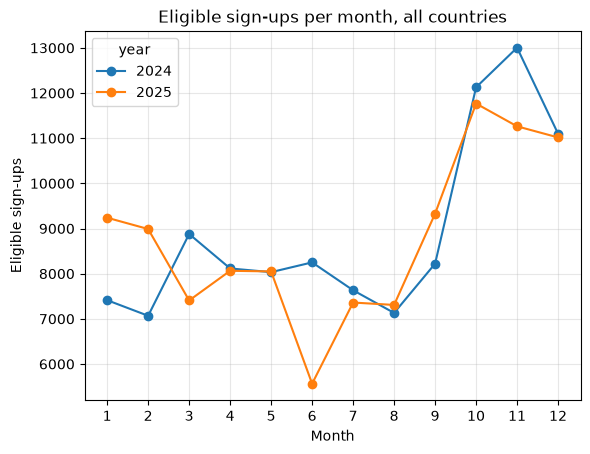

In [65]:
import matplotlib.pyplot as plt

monthly.plot(marker="o")
plt.title("Eligible sign-ups per month, all countries")
plt.xlabel("Month")
plt.ylabel("Eligible sign-ups")
plt.xticks(range(1, 13))
plt.grid(alpha=0.3)
plt.show()

In [66]:
june = elig[elig["month"] == 6]
june_by_country = june.groupby(["Country", "year"]).size().unstack()
june_by_country["ratio"] = (june_by_country[2025] / june_by_country[2024]).round(2)
june_by_country.sort_values("ratio")

year,2024,2025,ratio
Country,,,
Argentina,69,35,0.51
Turkey,166,95,0.57
Mexico,407,241,0.59
France,322,192,0.60
South Africa,255,153,0.60
Canada,384,231,0.60
Vietnam,423,257,0.61
Australia,353,228,0.65
Indonesia,135,89,0.66


In [67]:
june25_days = june[june["year"] == 2025].groupby("Sign_Up_Date").size()
print("Days with data:", len(june25_days))
june25_days.describe()

Days with data: 30


count     30.000000
mean     185.466667
std      133.152682
min       24.000000
25%       69.500000
50%      147.000000
75%      315.750000
max      471.000000
dtype: float64

*June 2025 was about 30% below June 2024 in all 22 countries, with no missing days. We can’t tell whether it’s a one-off, so the forecast averages 2024 and 2025, which softens its effect.*

<b>The 2026 forecast</b>

In [71]:
import calendar

counts = elig.groupby(["Country", "year", "month"]).size().reset_index(name="signups")
counts

,Country,year,month,signups
0,Argentina,2024,1,53
1,Argentina,2024,2,66
2,Argentina,2024,3,69
3,Argentina,2024,4,71
4,Argentina,2024,5,67
...,...,...,...,...
523,Vietnam,2025,8,311
524,Vietnam,2025,9,419
525,Vietnam,2025,10,517
526,Vietnam,2025,11,529


In [72]:
counts["days"] = counts.apply(lambda r: calendar.monthrange(r["year"], r["month"])[1], axis=1)
counts["days"]

0      31
1      29
2      31
3      30
4      31
       ..
523    31
524    30
525    31
526    30
527    31
Name: days, Length: 528, dtype: int64

In [73]:
counts["per_day"] = counts["signups"] / counts["days"]
counts.head()

,Country,year,month,signups,days,per_day
0,Argentina,2024,1,53,31,1.709677
1,Argentina,2024,2,66,29,2.275862
2,Argentina,2024,3,69,31,2.225806
3,Argentina,2024,4,71,30,2.366667
4,Argentina,2024,5,67,31,2.161290


In [74]:
forecast = counts.groupby(["Country", "month"])["per_day"].mean().reset_index()
forecast = forecast.rename(columns={"Country": "country", "per_day": "daily_eligible_base"})

forecast["daily_eligible_low"]  = forecast["daily_eligible_base"] * 0.85
forecast["daily_eligible_high"] = forecast["daily_eligible_base"] * 1.15

avg_budget = elig.groupby("Country")["Projected_Annual_Budget"].mean()
forecast["avg_eligible_budget"] = forecast["country"].map(avg_budget)

print(forecast.shape)
forecast.head(13)

(264, 6)


,country,month,daily_eligible_base,daily_eligible_low,daily_eligible_high,avg_eligible_budget
0,Argentina,1,2.306452,1.960484,2.652419,11131.831947
1,Argentina,2,2.495074,2.120813,2.869335,11131.831947
2,Argentina,3,2.064516,1.754839,2.374194,11131.831947
3,Argentina,4,2.500000,2.125000,2.875000,11131.831947
4,Argentina,5,2.129032,1.809677,2.448387,11131.831947
5,Argentina,6,1.733333,1.473333,1.993333,11131.831947
6,Argentina,7,2.354839,2.001613,2.708065,11131.831947
7,Argentina,8,2.145161,1.823387,2.466935,11131.831947
8,Argentina,9,2.166667,1.841667,2.491667,11131.831947
9,Argentina,10,3.225806,2.741935,3.709677,11131.831947


*  forecast rule: for each country and month, take the average of 2024 and 2025. For example, 2026 January = average of January 2024 and January 2025. 

* renames the columns to match the agreed interface in the README, so the simulator can read the file.
    
* Low and high scenarios are 15% below and above base. These feed the sensitivity analysis the hackathon asks for.

* avg_eligible_budget is the average budget of eligible advertisers per country. The simulator needs it to calculate revenue uplift. .map() looks up each row’s country in avg_budget


In [89]:
forecast["agents_needed"] = forecast["daily_eligible_base"] * 6


In [86]:
forecast

,country,month,daily_eligible_base,daily_eligible_low,daily_eligible_high,avg_eligible_budget,agents_needed
0,Argentina,1,2.306452,1.960484,2.652419,11131.831947,13.838710
1,Argentina,2,2.495074,2.120813,2.869335,11131.831947,14.970443
2,Argentina,3,2.064516,1.754839,2.374194,11131.831947,12.387097
3,Argentina,4,2.500000,2.125000,2.875000,11131.831947,15.000000
4,Argentina,5,2.129032,1.809677,2.448387,11131.831947,12.774194
...,...,...,...,...,...,...,...
259,Vietnam,8,9.854839,8.376613,11.333065,17302.530269,59.129032
260,Vietnam,9,13.050000,11.092500,15.007500,17302.530269,78.300000
261,Vietnam,10,18.032258,15.327419,20.737097,17302.530269,108.193548
262,Vietnam,11,18.516667,15.739167,21.294167,17302.530269,111.100000


In [90]:
need_table = forecast.pivot(index="country", columns="month", values="agents_needed").round()
need_table

month,1,2,3,4,5,6,7,8,9,10,11,12
country,,,,,,,,,,,,
Argentina,14.0,15.0,12.0,15.0,13.0,10.0,14.0,13.0,13.0,19.0,20.0,19.0
Australia,69.0,69.0,67.0,73.0,69.0,58.0,62.0,60.0,78.0,101.0,114.0,93.0
Brazil,84.0,90.0,87.0,91.0,90.0,73.0,74.0,78.0,94.0,126.0,126.0,114.0
Canada,72.0,73.0,68.0,71.0,72.0,62.0,62.0,61.0,76.0,100.0,110.0,103.0
China,89.0,93.0,86.0,87.0,86.0,74.0,80.0,72.0,97.0,130.0,131.0,118.0
France,62.0,69.0,63.0,66.0,64.0,51.0,58.0,56.0,70.0,89.0,92.0,83.0
Germany,83.0,84.0,72.0,82.0,79.0,70.0,74.0,73.0,93.0,114.0,125.0,109.0
India,224.0,236.0,217.0,218.0,210.0,188.0,197.0,194.0,236.0,308.0,334.0,284.0
Indonesia,29.0,27.0,25.0,26.0,31.0,22.0,26.0,25.0,32.0,39.0,41.0,36.0


In [81]:
peak = pd.DataFrame({
    "existing":   staff,
    "avg_need":   need_table.mean(axis=1).round(),
    "peak_need":  need_table.max(axis=1),
    "peak_month": need_table.idxmax(axis=1),
})
peak["extra_vs_peak"] = peak["existing"] - peak["peak_need"]
print(peak[["existing", "avg_need", "peak_need"]].sum())
peak.sort_values("extra_vs_peak", ascending=False)

existing     6474.0
avg_need     1743.0
peak_need    2429.0
dtype: float64


,existing,avg_need,peak_need,peak_month,extra_vs_peak
Germany,602,88.0,125.0,11,477.0
UK,589,102.0,142.0,11,447.0
France,489,69.0,92.0,11,397.0
USA,652,214.0,296.0,11,356.0
Australia,450,76.0,114.0,11,336.0
Mexico,442,81.0,114.0,11,328.0
UAE,309,16.0,24.0,11,285.0
Italy,350,84.0,119.0,11,231.0
Argentina,200,15.0,20.0,11,180.0
Japan,297,110.0,154.0,11,143.0


In [82]:
import os

os.makedirs("../data/processed", exist_ok=True)
forecast.drop(columns="agents_needed").to_csv("../data/processed/forecast.csv", index=False)
print("Saved!")

Saved!


<b>The story in one sentence: even if Google staffed every country for its busiest month (November), it would need only about 2,430 agents instead of 6,474, and Vietnam is the only country that needs more.</b>